# IST_robot：固定基座六维载荷与被动羽化实验

本 notebook 实际执行 CPU 仿真，生成 **MP4 视频、CSV/NPZ 原始数据和 PNG 图**。
`base_link` 固定于世界；电机由角速度闭环产生力矩，经齿轮与滑块带动扑翼。
feathering 没有主动执行器、角度覆盖或人为新增的弹簧。

**朝向修正：** CAD 的翼机构位于基座的 −Z 一侧，现在装配体绕 X 旋转 180°，
使翼机构位于世界 +Z 上方。URDF 的 CAD 内部坐标不变，MJCF 只改变根刚体装配姿态。

**关于“只向一个方向偏转”：** 完整周期诊断表明原模型也能跨过正负羽化角。
输入轴 100 rad/s 经 16:1 减速后只有约 0.995 Hz；观察短仿真时间时可能仅看到半行程。
正立后重力矩方向也会改变。这里保留真实被动响应，用多周期曲线和慢放视频验证翻转。
结果反映当前简化气动模型，并非实机标定结果。

In [1]:
import os
os.environ.setdefault("MUJOCO_GL", "egl")  # 必须在 import mujoco 之前设置
from pathlib import Path
import sys
import json
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Video, Image, Markdown
%matplotlib inline

here = Path.cwd().resolve()
ROOT = next(p for p in (here, *here.parents) if (p / "flapsim" / "simulator.py").is_file())
EXPERIMENT = ROOT / "experiments" / "fixbase"
sys.path.insert(0, str(ROOT))
sys.path.insert(0, str(EXPERIMENT))
from experiment import ExperimentConfig, run_experiment, plot_results, AXES
OUTPUT = EXPERIMENT / "results"
print("输出目录：", OUTPUT)

输出目录： /home/robot/rl/FlapSim/experiments/fixbase/results


## 参数和复现

默认仿真 1.2 s，物理步长 5 µs，500 rad/s 输入轴指令，前 0.1 s 平滑升速。
理论无负载扑翼频率为 `500 / (16 × 2π) ≈ 4.97 Hz`，实际转速由动力学决定。
原始测量以 2 kHz 采样；图中的冲击峰值仅是该采样率下的测量值，不代表连续时间峰值。

视频按 250 个仿真帧/s 捕获、30 fps 播放，约 **8.33 倍慢放**。
字幕时间是仿真时间，镜头为整机和机构近景。没有打开 viewer 窗口。
第一次或修改参数后设 `RUN_SIMULATION=True`；只查看已有结果可设为 `False`。

In [2]:
PARAMETERS = ExperimentConfig(duration=1.2, motor_speed=500.0, ramp_time=0.1)
RUN_SIMULATION = False

if RUN_SIMULATION:
    data, summary = run_experiment(OUTPUT, PARAMETERS, video=True)
else:
    with np.load(OUTPUT / "measurements.npz") as saved:
        data = {key: saved[key] for key in saved.files}
    summary = json.loads((OUTPUT / "summary.json").read_text())

print("记录点数：", summary["samples"])
print("实测机构周期数：", round(summary["wing_cycles_measured"], 3))
print("稳态区间平均输入轴转速：", round(summary["mean_motor_speed_after_025s"], 3), "rad/s")

记录点数： 2401
实测机构周期数： 5.375
稳态区间平均输入轴转速： 469.45 rad/s


## Headless 视频回放

蓝色为左翼，橙色为右翼；左右关节坐标是镜像定义，因此原始 feathering 角通常符号相反。
视频嵌入 notebook，同时保留独立 `results/fixbase.mp4`。

In [3]:
display(Video(str(OUTPUT / "fixbase.mp4"), embed=True, width=1100,
              html_attributes="controls loop muted"))

## 六维力和力矩：一个 figure，六个子图

统一顺序 `[Fx, Fy, Fz, Mx, My, Mz]`，单位为 N、N·m；分量采用世界坐标轴，
力矩参考点统一为 **base_link 原点**。

- **Aerodynamic wrench**：左右翼的叶素气动力，连同相对于基座的力臂矩。
- **Robot on fixture (total)**：机器人作用于固定支架的总载荷，包含重力、气动和机构惯性效应。
- **Fixture load minus gravity**：总支架载荷减去当前构型下的重量及重力矩。

主 figure 同时展示左右翼及整机的六维气动力和力矩。
支架反力另放在下方同样的六轴 figure 中，保留机械限位的窄脉冲及其原始幅度，
不让这些脉冲把较小的气动力曲线压扁。设 `include_weight=True`
可在支架载荷图中加入含重量的总载荷；全部原始量始终保存在数据文件中。
2 kHz 采样无法精确刻画微秒级限位冲击的峰值；请勿将这些采样尖峰视为可靠的实机冲击预测。
关节处的父子相互作用载荷另存为 `*_parent_load_*`，参考点为各自关节锚点，不能直接相加。
电机的定子反力矩是内部力矩，也不能再次叠加到整机外部气动力上。

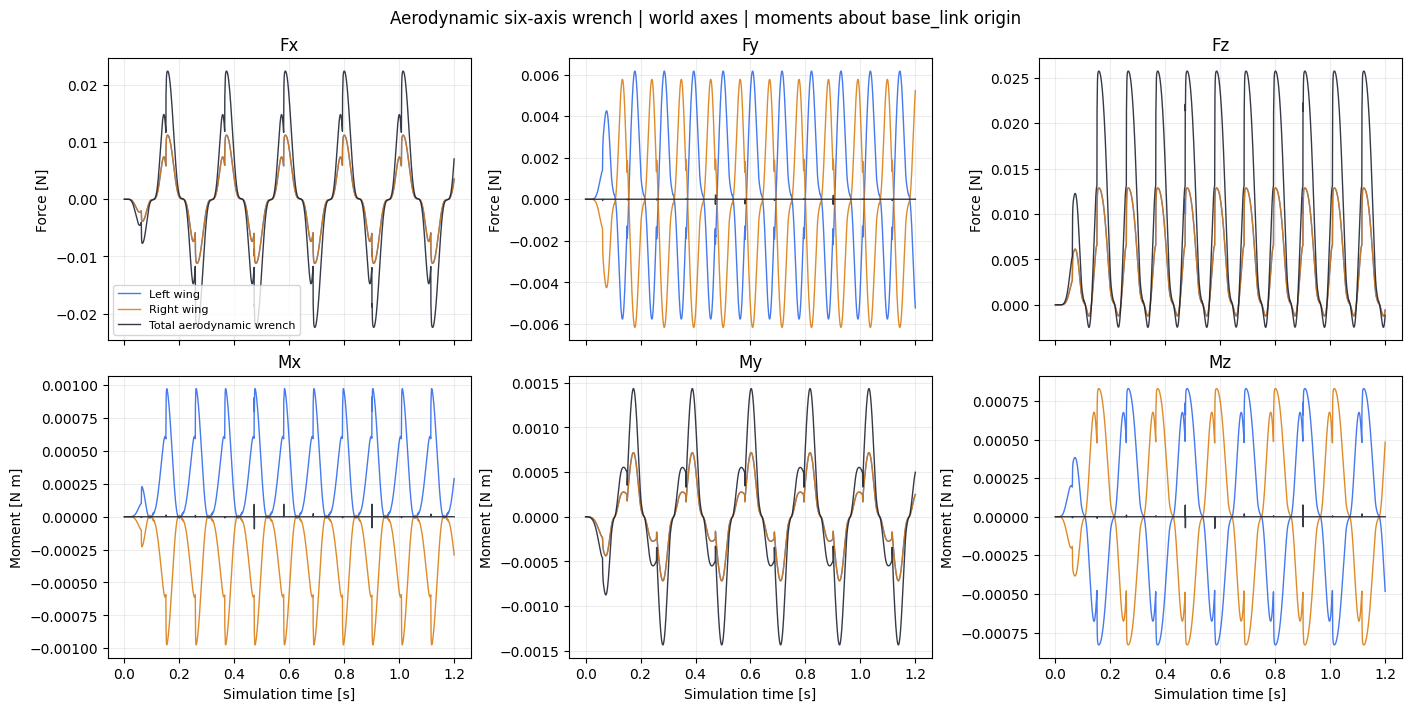

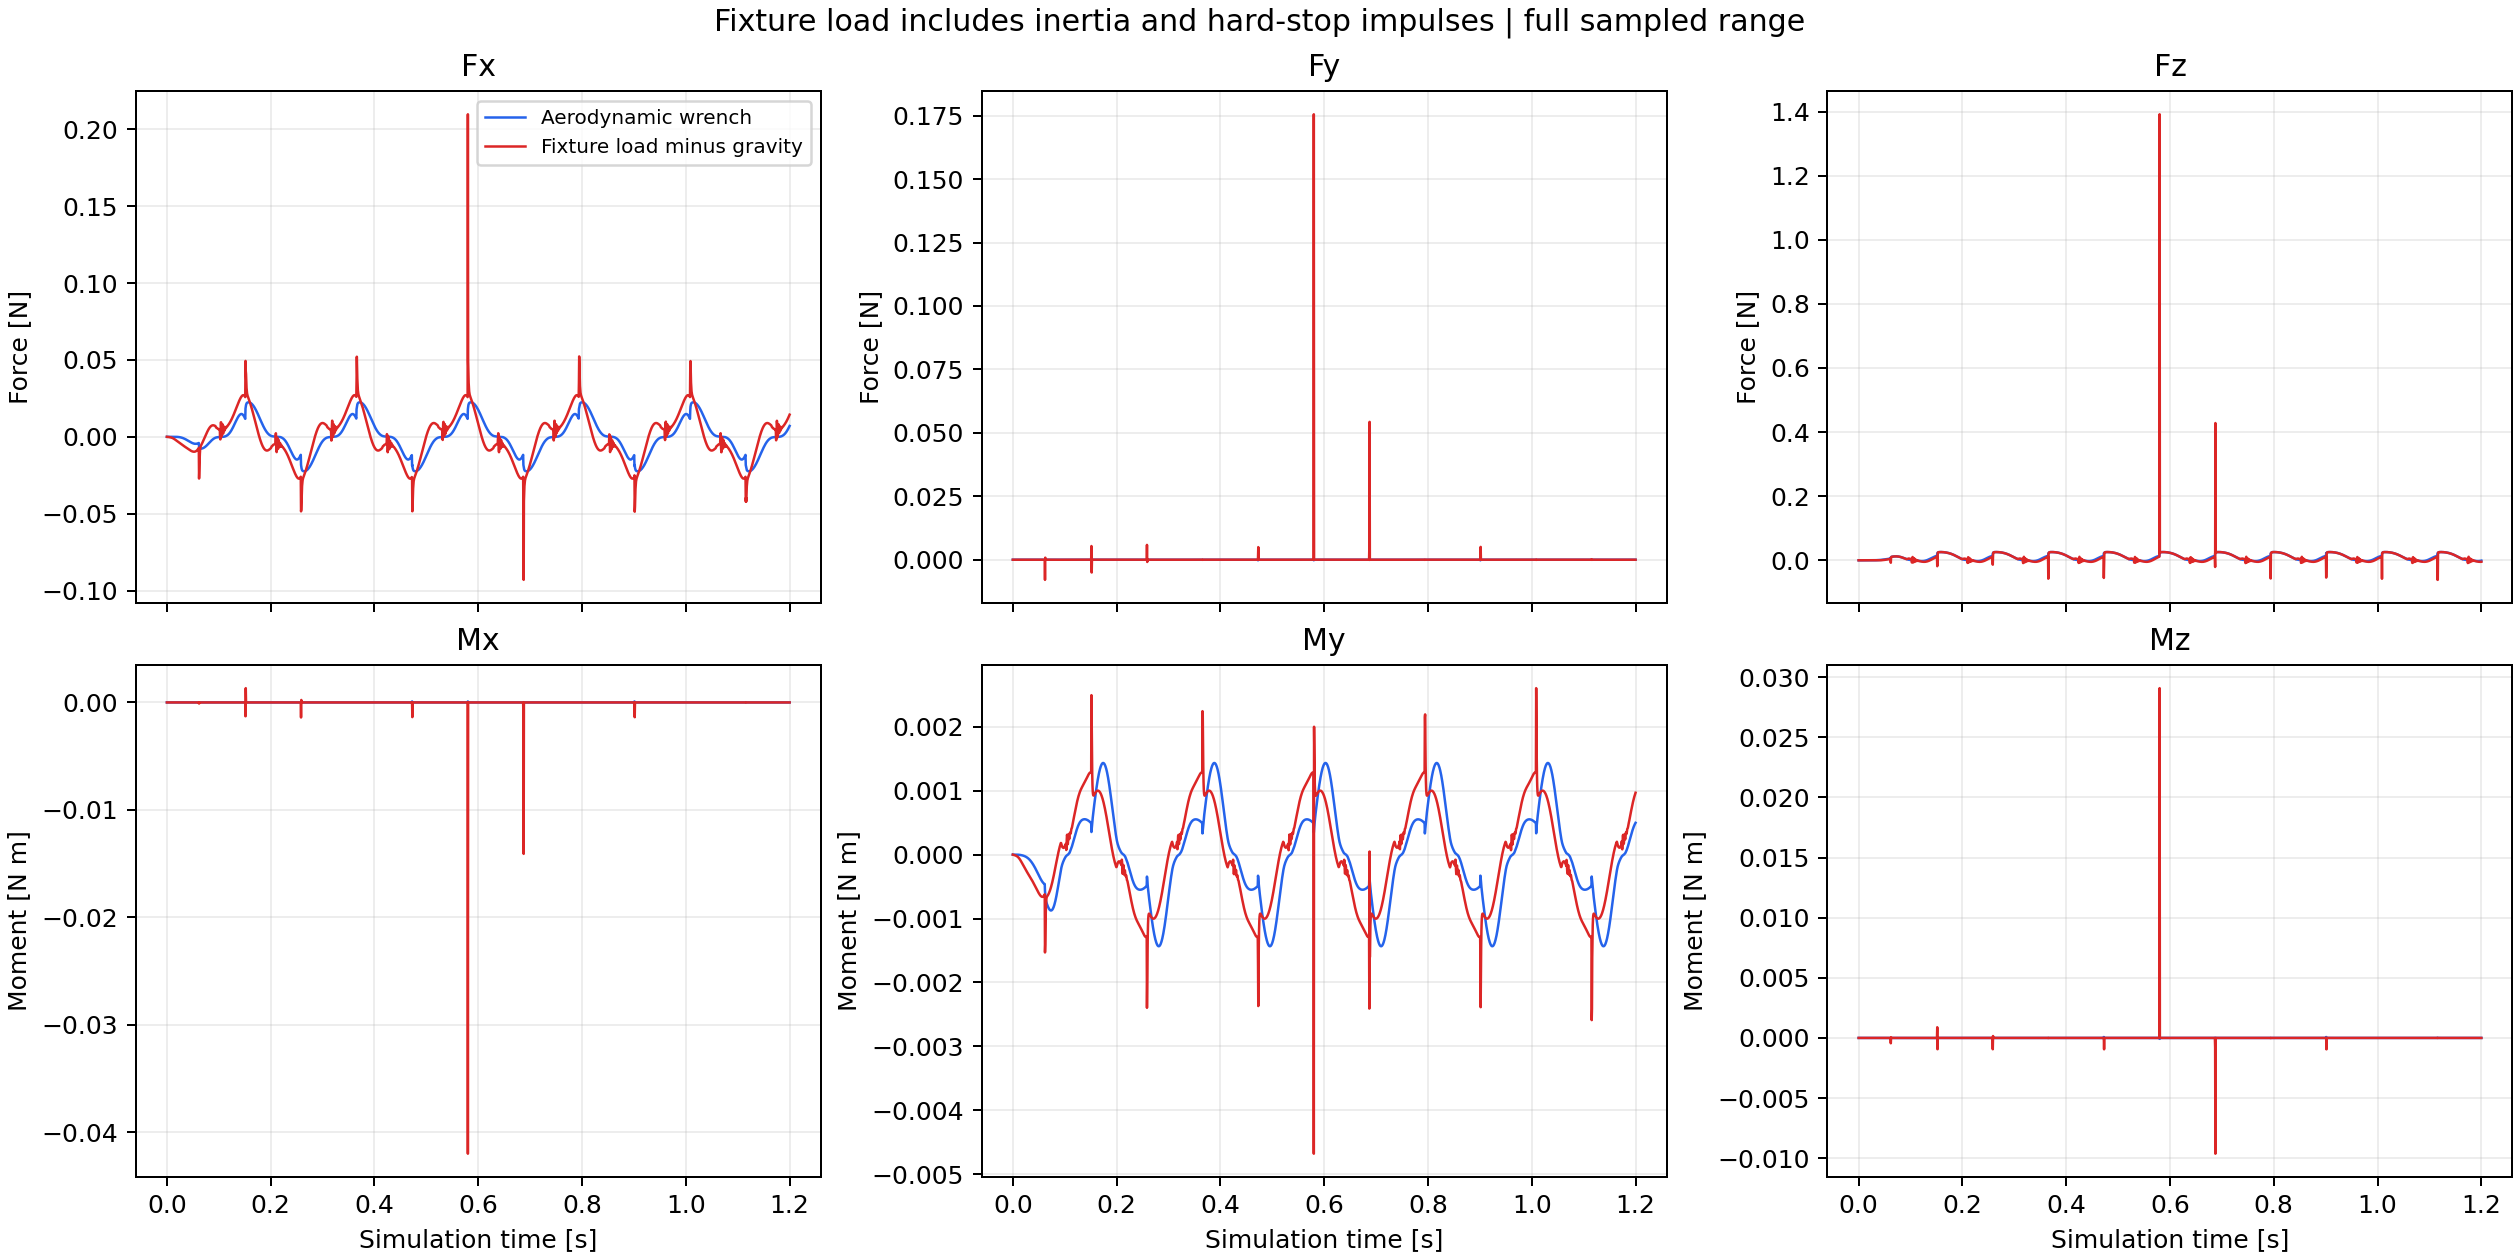

In [4]:
wrench_figure, motion_figure = plot_results(data, OUTPUT, include_weight=False)
plt.close(motion_figure)
display(wrench_figure)
plt.close(wrench_figure)
display(Image(filename=str(OUTPUT / "fixture_wrench_6d.png")))

## 电机、flapping 与 feathering

关节角均由动力学积分产生。羽化曲线触及 ±50° 表示进入原模型的机械限位，
不是软件裁剪角度；零弹簧刚度和被动关节设置保持不变。

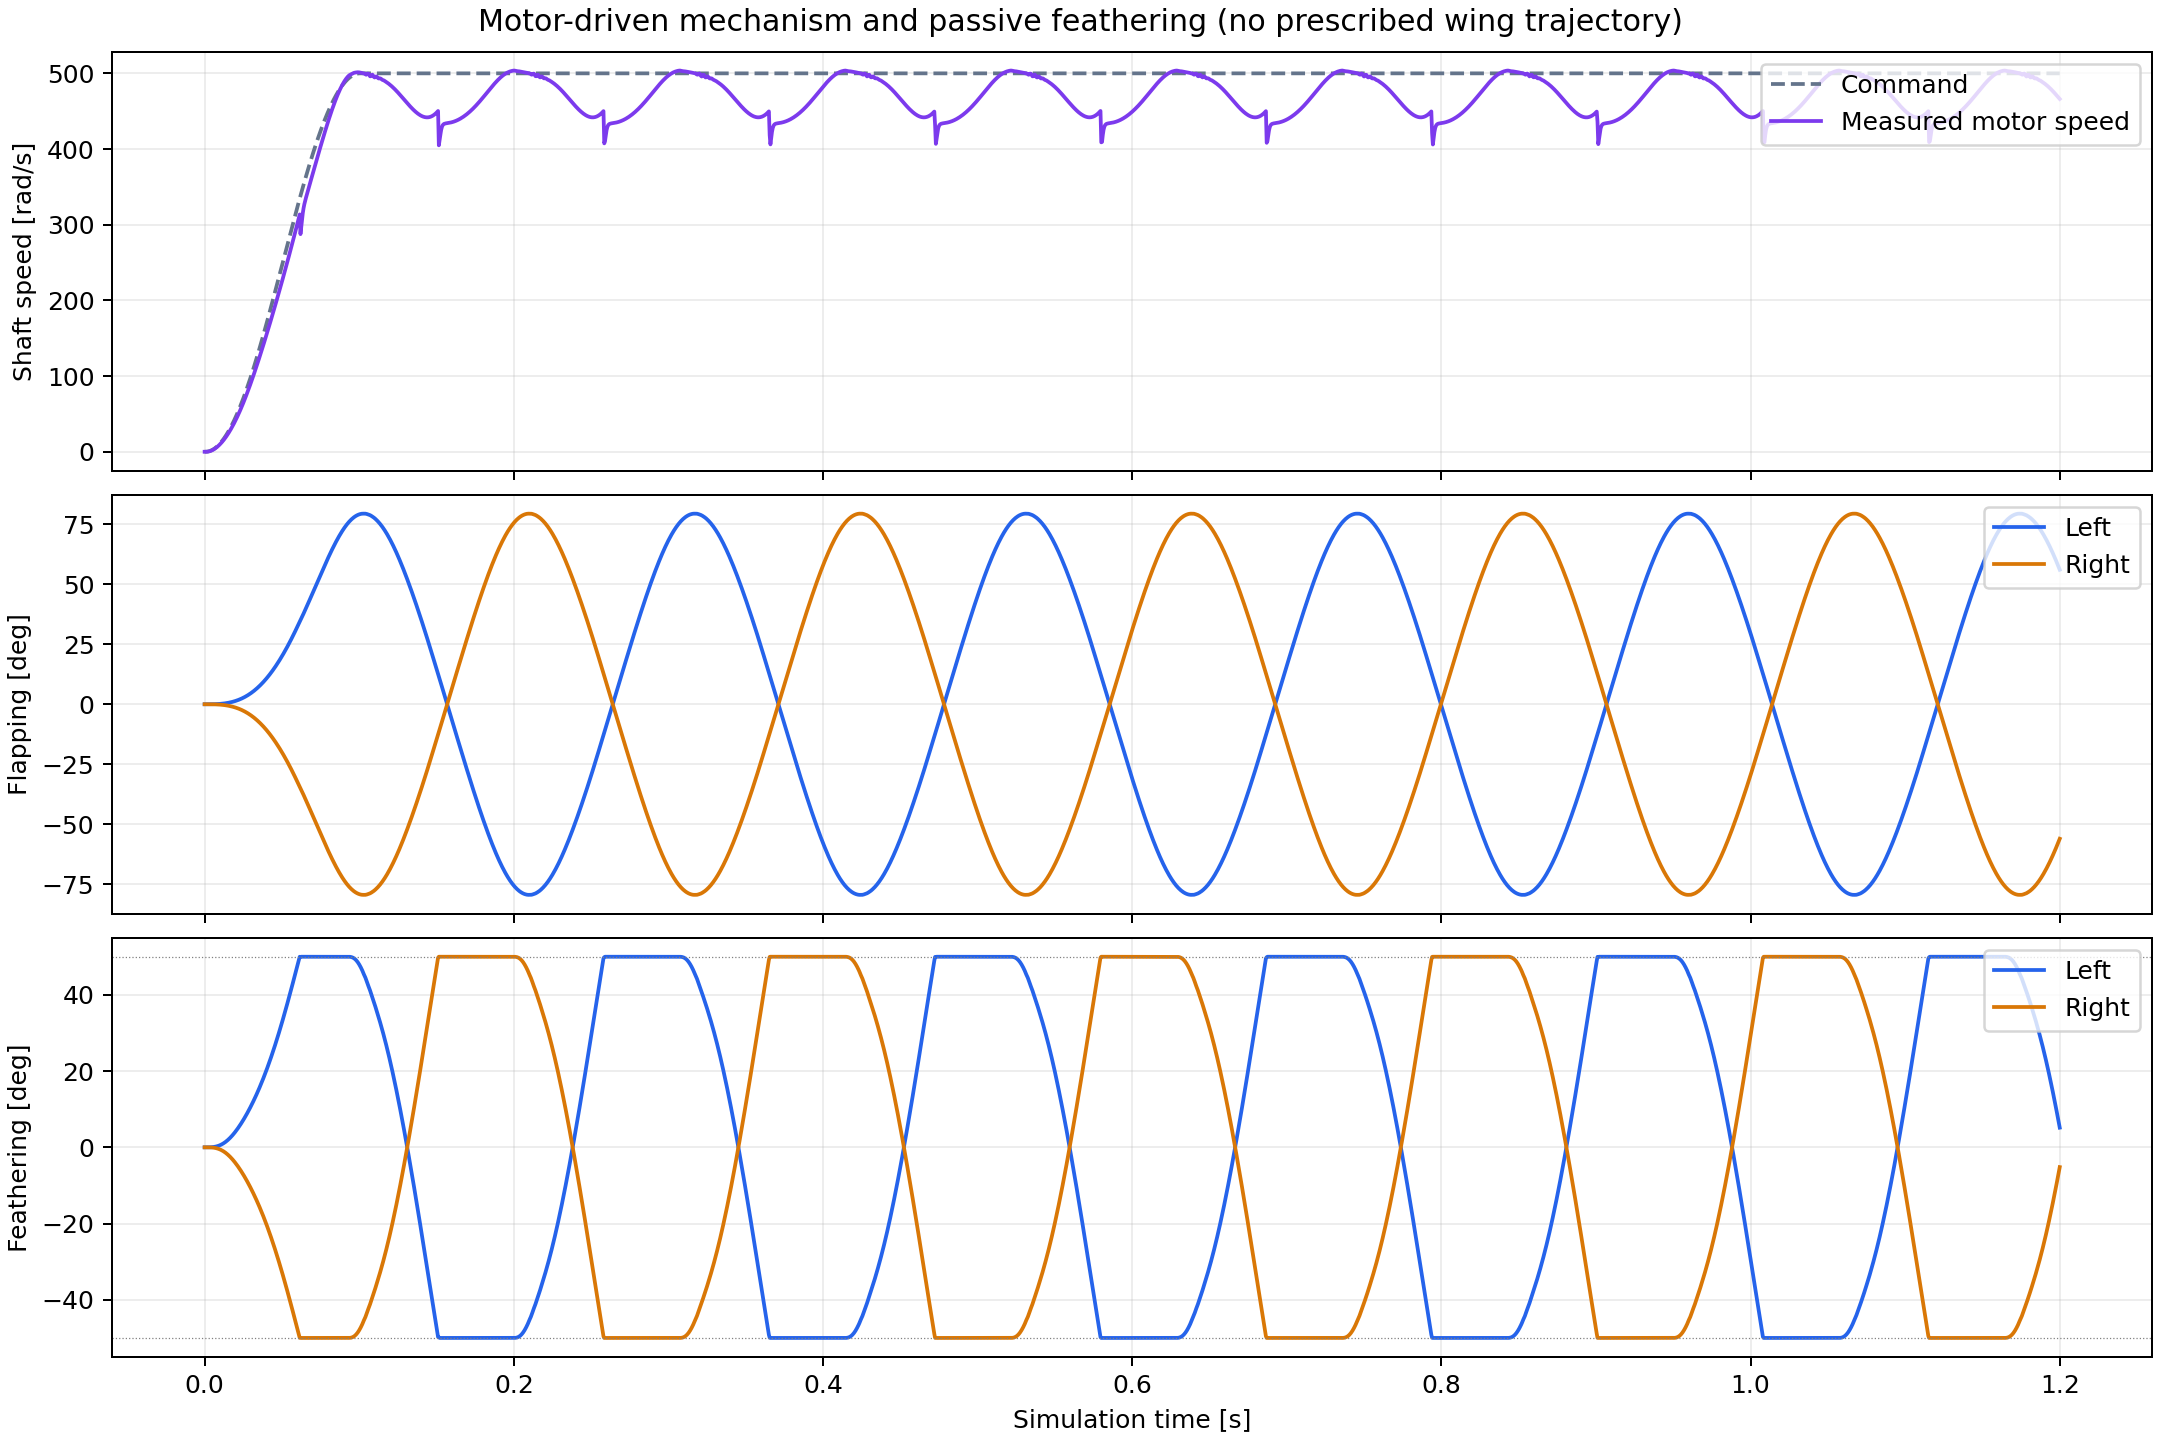

稳态羽化角最小值 [L, R] / deg： [-50.001223889973204, -50.00063899919241]
稳态羽化角最大值 [L, R] / deg： [50.00001278774166, 50.00028310559775]
跨正负 5° 的翻转次数 [L, R]： [8, 8]


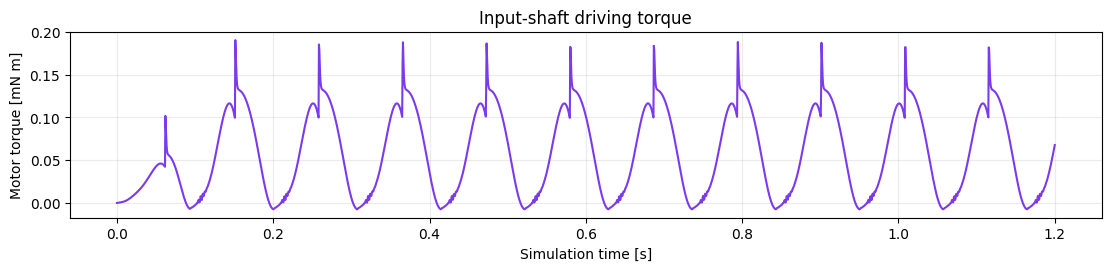

In [5]:
display(Image(filename=str(OUTPUT / "joint_motion.png")))
print("稳态羽化角最小值 [L, R] / deg：", summary["pitch_min_deg"])
print("稳态羽化角最大值 [L, R] / deg：", summary["pitch_max_deg"])
print("跨正负 5° 的翻转次数 [L, R]：", summary["pitch_reversals_after_025s"])

fig, ax = plt.subplots(figsize=(11, 2.6), layout="constrained")
ax.plot(data["time_s"], 1000*data["motor_torque_Nm"], color="#7c3aed")
ax.set(xlabel="Simulation time [s]", ylabel="Motor torque [mN m]", title="Input-shaft driving torque")
ax.grid(alpha=.25)
fig.savefig(OUTPUT / "motor_torque.png", dpi=150)
plt.show()

## 完整周期诊断与验证

下面的诊断对比旧朝向 100 rad/s、正立 100 rad/s 和正立 500 rad/s，
用于核对羽化是否真正只停留于一侧。诊断数据可用 `diagnose_feathering.py` 重做。

测力来自 MuJoCo 的递归牛顿–欧拉约束后计算；代码将内部 `[moment, force]` 排列转换为
`[force, moment]`，并把力矩从根子树质心平移到测量点。
符号已用静止的已知质量、偏置质心及外力单元测试验证。
参考 [MuJoCo force/torque sensor 定义](https://mujoco.readthedocs.io/en/3.8.0/XMLreference.html#sensor-force)
和 [cfrc_int 数据结构](https://mujoco.readthedocs.io/en/3.8.0/APIreference/APItypes.html)。

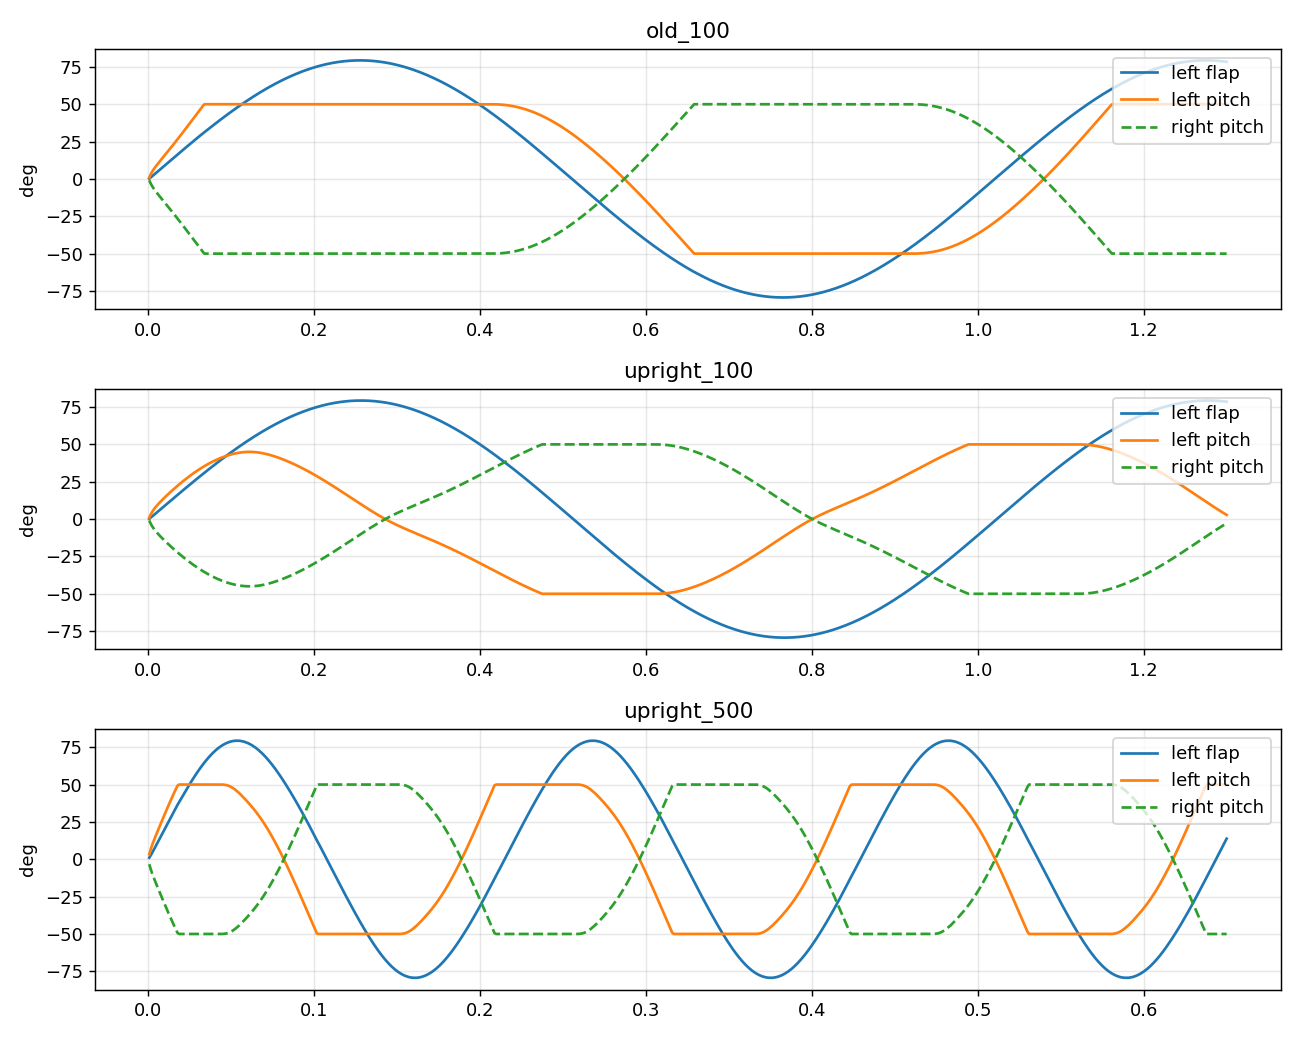

通过：基座不动、左右羽化均多次跨零翻转、数值有限、无 MuJoCo 数值警告。


| 分量 | t ≥ 0.25 s 区间均值 | 单位 |
|---|---:|---|
| Fx | -0.000760894 | N |
| Fy | 9.98171e-08 | N |
| Fz | 0.00986901 | N |
| Mx | 1.18745e-07 | N·m |
| My | -5.09296e-05 | N·m |
| Mz | 1.1282e-08 | N·m |

注意：该时间窗均值并非严格整周期均值，也不是悬停能力验证。


In [6]:
if (OUTPUT / "diagnosis.png").is_file():
    display(Image(filename=str(OUTPUT / "diagnosis.png")))

assert summary["max_base_pose_error"] < 1e-12
assert all(count >= 4 for count in summary["pitch_reversals_after_025s"])
assert all(v < -5 for v in summary["pitch_min_deg"])
assert all(v > 5 for v in summary["pitch_max_deg"])
assert not any(summary["numerical_warnings"])
assert all(np.isfinite(v).all() for v in data.values())
print("通过：基座不动、左右羽化均多次跨零翻转、数值有限、无 MuJoCo 数值警告。")

mean_wrench = summary["mean_aero_wrench_after_025s"]
display(Markdown("| 分量 | t ≥ 0.25 s 区间均值 | 单位 |\n|---|---:|---|\n" +
    "\n".join(f"| {axis} | {value:.6g} | {'N' if axis[0]=='F' else 'N·m'} |"
              for axis, value in zip(AXES, mean_wrench))))
print("注意：该时间窗均值并非严格整周期均值，也不是悬停能力验证。")

## 文件

- `results/measurements.csv` / `.npz`：采样时间、轴指令、5 个关节角/速度、电机力矩、各类六维载荷。
- `results/fixbase.mp4`：双视角慢放视频；`fixbase.png`：首帧。
- `results/wrench_6d.png`：六维力和力矩的同一 figure。
- `results/fixture_wrench_6d.png`：支架反力矩，保留限位冲击的完整采样范围。
- `results/joint_motion.png`、`motor_torque.png`：运动和驱动力矩。
- `results/summary.json`：参数、版本、翻转统计、数值检查。

修改气动参数、电机参数、几何或安装姿态后需要重新运行，不能直接沿用这里的载荷数值。